<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# M07 Rapid building machine learning workflow - Rapid EDA

---
<small>© 2026 Decoded Limited. All rights reserved. Website: https://decoded.com </small>

### Rapid EDA with ydata-profiling
Welcome! Exploratory Data Analysis (EDA) is a crucial first step in any machine learning project. However, writing individual lines of code to check distributions, correlations, and outliers for *every single column* can be incredibly tedious.

Enter **`ydata-profiling`**. In just a few lines of code, it generates a comprehensive, interactive HTML report of your dataset. 

In this notebook, we will use it to perform rapid EDA on the **Juice** (Classification) and **Insurance** (Regression) datasets we used in our previous PyCaret modeling modules.

In [12]:
# Install dependencies (uncomment if running for the first time in this environment)
# !pip install ydata-profiling pycaret

In [1]:
# Import libraries 
%matplotlib inline
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
from pycaret.datasets import get_data
from ydata_profiling import ProfileReport

## 0. Loading The Data From A SQLlite Database

#### Connecting the database

In [2]:
import sqlite3
import pandas as pd
conn = sqlite3.connect("data_class.db")

#### What does this database contain?

In [3]:
# what tables does this 
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';",conn)
tables

,name


Now we know the tables found in this database. Let's investigate more about the table

## 1. Loading the Data


In [4]:
### Import all rows from the table using read_sql in pandas
juice_data = pd.read_sql("SELECT * FROM purchases", conn)

DatabaseError: Execution failed on sql 'SELECT * FROM purchases': no such table: purchases

In [5]:
#Load Classification Data
juice_data.head()

NameError: name 'juice_data' is not defined

In [134]:
#Citrus Hill and Minute Maid
juice_data["Purchase"].value_counts()

Purchase
CH    653
MM    417
Name: count, dtype: int64

## 2. Generating the Profile Reports
Instead of writing dozens of `df.describe()` and `df.hist()` commands, we pass our dataframes into `ProfileReport`.

*Note: To save memory in the notebook, we will export the report as an HTML file.*

In [33]:
# --- Profile the Juice Dataset ---
juice_profile = ProfileReport(juice_data, title="Juice Dataset EDA Report", explorative=True)
juice_profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 19/19 [00:00<00:00, 81903.16it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Now that we have alleviated the need for extensive plots we can now focus on the decision making needed for modelling before this let us just quickly check the data

### 0. Data Familiarization (Sanity Check)

What is the shape of the data?
→ Determines scale and modeling constraints
→ ✅ Choose model complexity, validation strategy

In [135]:
# Shape of data (rows, columns)
juice_data.shape

(1070, 19)

What does a sample look like?
→ Reveals structure and obvious issues
→ ✅ Identify target, IDs, feature types

In [136]:
juice_data.head()

,Id,Purchase,WeekofPurchase,StoreID,PriceCH,PriceMM,DiscCH,DiscMM,SpecialCH,SpecialMM,LoyalCH,SalePriceMM,SalePriceCH,PriceDiff,Store7,PctDiscMM,PctDiscCH,ListPriceDiff,STORE
0,1,CH,237,1,1.75,1.99,0.00,0.0,0,0,0.500000,1.99,1.75,0.24,No,0.000000,0.000000,0.24,1
1,2,CH,239,1,1.75,1.99,0.00,0.3,0,1,0.600000,1.69,1.75,-0.06,No,0.150754,0.000000,0.24,1
2,3,CH,245,1,1.86,2.09,0.17,0.0,0,0,0.680000,2.09,1.69,0.40,No,0.000000,0.091398,0.23,1
3,4,MM,227,1,1.69,1.69,0.00,0.0,0,0,0.400000,1.69,1.69,0.00,No,0.000000,0.000000,0.00,1
4,5,CH,228,7,1.69,1.69,0.00,0.0,0,0,0.956535,1.69,1.69,0.00,Yes,0.000000,0.000000,0.00,0


Are data types correct?
→ Affects all downstream processing
→ ✅ Fix dtypes, separate feature groups

In [137]:
# Data types
juice_data.dtypes

Id                  int64
Purchase           object
WeekofPurchase      int64
StoreID             int64
PriceCH           float64
PriceMM           float64
DiscCH            float64
DiscMM            float64
SpecialCH           int64
SpecialMM           int64
LoyalCH           float64
SalePriceMM       float64
SalePriceCH       float64
PriceDiff         float64
Store7             object
PctDiscMM         float64
PctDiscCH         float64
ListPriceDiff     float64
STORE               int64
dtype: object

Any obvious anomalies?
→ Early detection of data issues
→ ✅ Flag problems for deeper analysis later

In [138]:
# Data types
juice_data.describe()

,Id,WeekofPurchase,StoreID,PriceCH,PriceMM,DiscCH,DiscMM,SpecialCH,SpecialMM,LoyalCH,SalePriceMM,SalePriceCH,PriceDiff,PctDiscMM,PctDiscCH,ListPriceDiff,STORE
count,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000
mean,535.500000,254.381308,3.959813,1.867421,2.085411,0.051860,0.123364,0.147664,0.161682,0.565782,1.962047,1.815561,0.146486,0.059298,0.027314,0.217991,1.630841
std,309.026698,15.558286,2.308984,0.101970,0.134386,0.117474,0.213834,0.354932,0.368331,0.307843,0.252697,0.143384,0.271563,0.101760,0.062232,0.107535,1.430387
min,1.000000,227.000000,1.000000,1.690000,1.690000,0.000000,0.000000,0.000000,0.000000,0.000011,1.190000,1.390000,-0.670000,0.000000,0.000000,0.000000,0.000000
25%,268.250000,240.000000,2.000000,1.790000,1.990000,0.000000,0.000000,0.000000,0.000000,0.325257,1.690000,1.750000,0.000000,0.000000,0.000000,0.140000,0.000000
50%,535.500000,257.000000,3.000000,1.860000,2.090000,0.000000,0.000000,0.000000,0.000000,0.600000,2.090000,1.860000,0.230000,0.000000,0.000000,0.240000,2.000000
75%,802.750000,268.000000,7.000000,1.990000,2.180000,0.000000,0.230000,0.000000,0.000000,0.850873,2.130000,1.890000,0.320000,0.112676,0.000000,0.300000,3.000000
max,1070.000000,278.000000,7.000000,2.090000,2.290000,0.500000,0.800000,1.000000,1.000000,0.999947,2.290000,2.090000,0.640000,0.402010,0.252688,0.440000,4.000000


## EDA informed Considerations 

### 1. Look at the Target Variable 

Binary or multi-class?
- Changes model type and evaluation approach

Missing target values?

- Invalid training samples
- ✅ Drop or fix before modeling

In [78]:
# 4. Check missing target values (code)
juice_data["Purchase"].isnull().sum()

0

Which metric reflects business goal?
- Accuracy can be misleading
- ✅ Choose F1, recall, precision, ROC-AUC, PR-AUC

### 2. Data Quality 

Shape of Data?
- how many rows do we have?
- how many columns?

In [141]:
juice_data.shape

(1070, 19)

Incorrect data types?
→ Misleads models (e.g., numeric treated as categorical)
→ ✅ Fix dtype → impacts encoding + model input

In [142]:
juice_data.dtypes

Id                  int64
Purchase           object
WeekofPurchase      int64
StoreID             int64
PriceCH           float64
PriceMM           float64
DiscCH            float64
DiscMM            float64
SpecialCH           int64
SpecialMM           int64
LoyalCH           float64
SalePriceMM       float64
SalePriceCH       float64
PriceDiff         float64
Store7             object
PctDiscMM         float64
PctDiscCH         float64
ListPriceDiff     float64
STORE               int64
dtype: object

→ Missingness can carry signal or introduce bias*
→ ✅ Choose imputation strategy (mean, median, model-based, or flag)

In [155]:
# Missing values (proportion)
juice_data.isnull().sum().sort_values(ascending=False)

Id                 0
Purchase           0
WeekofPurchase     0
StoreID            0
PriceCH            0
PriceMM            0
DiscCH             0
DiscMM             0
SpecialCH          0
SpecialMM          0
LoyalCH            0
SalePriceMM        0
SalePriceCH        0
PriceDiff          0
Store7             0
PctDiscMM          0
PctDiscCH          0
ListPriceDiff      0
STORE              0
Purchase_binary    0
dtype: int64

Are there constant / near-constant columns?
→ No predictive value

In [144]:
constant_cols = [col for col in juice_data.columns if juice_data[col].nunique() <= 1]

Duplicate rows?
→ Can bias model and inflate performance
→ ✅ Remove duplicates

In [145]:
# Count duplicates
juice_data.duplicated().sum()

0

In [ ]:
# Drop duplicates
juice_data = juice_data.drop_duplicates() 

- we can drop duplicates before train/test split

In [147]:
juice_data.shape

(1070, 19)

High-cardinality categorical features?***
→ Can explode feature space
→ ✅ Choose encoding (target encoding, embeddings)

In [148]:
# Number of unique values per column
juice_data.nunique().sort_values().head()

Purchase     2
Store7       2
SpecialMM    2
SpecialCH    2
StoreID      5
dtype: int64

### 3. Feature Distributions 

Are numeric features skewed?

In [92]:
# Skewness of numeric features
juice_data.skew(numeric_only=True).sort_values(ascending=False)

PctDiscCH         2.422300
DiscCH            2.416340
SpecialCH         1.989092
SpecialMM         1.840470
DiscMM            1.594784
PctDiscMM         1.539491
StoreID           0.311245
STORE             0.249493
PriceCH           0.064416
Id                0.000000
WeekofPurchase   -0.210990
LoyalCH          -0.278889
ListPriceDiff    -0.645208
PriceDiff        -0.759778
SalePriceMM      -0.797164
SalePriceCH      -0.952651
PriceMM          -1.461851
dtype: float64

Are numeric features on very different scales?
→ Some models are sensitive to magnitude, so large-scale variables can dominate learning

- based on this when we do our train test split we may expect to applying a transform later 

In [94]:
juice_data.describe().T[["min", "max"]]

,min,max
Id,1.000000,1070.000000
WeekofPurchase,227.000000,278.000000
StoreID,1.000000,7.000000
PriceCH,1.690000,2.090000
PriceMM,1.690000,2.290000
DiscCH,0.000000,0.500000
DiscMM,0.000000,0.800000
SpecialCH,0.000000,1.000000
SpecialMM,0.000000,1.000000
LoyalCH,0.000011,0.999947


Are categorical variables dominated by few values?*

→ Low information content


In [149]:
for col in juice_data.select_dtypes(include='object').columns:
    print(f"\nColumn: {col}")
    print(juice_data[col].value_counts(normalize=True).head())


Column: Purchase
Purchase
CH    0.61028
MM    0.38972
Name: proportion, dtype: float64

Column: Store7
Store7
No     0.66729
Yes    0.33271
Name: proportion, dtype: float64


- remember not to drop

### 4. Feature vs Target Relationships (Signal Detection) 

**Do features separate classes clearly?**
→ Indicates strong predictive power → ✅ Prioritize these features * 

In [150]:
juice_data.groupby("Purchase").mean(numeric_only=True).T

Purchase,CH,MM
Id,490.718224,605.625899
WeekofPurchase,255.941807,251.937650
StoreID,4.425727,3.230216
PriceCH,1.869296,1.864484
PriceMM,2.101424,2.060336
DiscCH,0.068867,0.025228
DiscMM,0.094855,0.168010
SpecialCH,0.185299,0.088729
SpecialMM,0.110260,0.242206
LoyalCH,0.723294,0.319128


In [151]:
# Correlation with target (if binary: 0/1)
juice_data["Purchase_binary"] = juice_data["Purchase"].map({
    "CH": 1,
    "MM": 0
})

**No visible relationship?** 
→ Likely noise → ✅ Drop or deprioritize * 

In [152]:
juice_data.corr(numeric_only=True)["Purchase_binary"].sort_values()

Id                -0.181425
SpecialMM         -0.174784
DiscMM            -0.166921
PctDiscMM         -0.166459
SalePriceCH       -0.132126
STORE             -0.124573
PriceCH            0.023021
WeekofPurchase     0.125572
SpecialCH          0.132751
PriceMM            0.149180
ListPriceDiff      0.164599
DiscCH             0.181249
PctDiscCH          0.182201
SalePriceMM        0.220584
StoreID            0.252625
PriceDiff          0.275022
LoyalCH            0.640582
Purchase_binary    1.000000
Name: Purchase_binary, dtype: float64

### 5. Correlation & Redundancy (Between Features)

Highly correlated features?

→ Redundant information
→ ✅ Drop one (simpler model, avoids multicollinearity)

In [153]:
corr = juice_data.corr(numeric_only=True).abs()
corr[corr > 0.8]

,Id,WeekofPurchase,StoreID,PriceCH,PriceMM,DiscCH,DiscMM,SpecialCH,SpecialMM,LoyalCH,SalePriceMM,SalePriceCH,PriceDiff,PctDiscMM,PctDiscCH,ListPriceDiff,STORE,Purchase_binary
Id,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeekofPurchase,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StoreID,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PriceCH,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PriceMM,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DiscCH,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.999022,NaN,NaN,NaN
DiscMM,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,0.846868,NaN,0.823908,0.998793,NaN,NaN,NaN,NaN
SpecialCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SpecialMM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LoyalCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- lets make this abit better

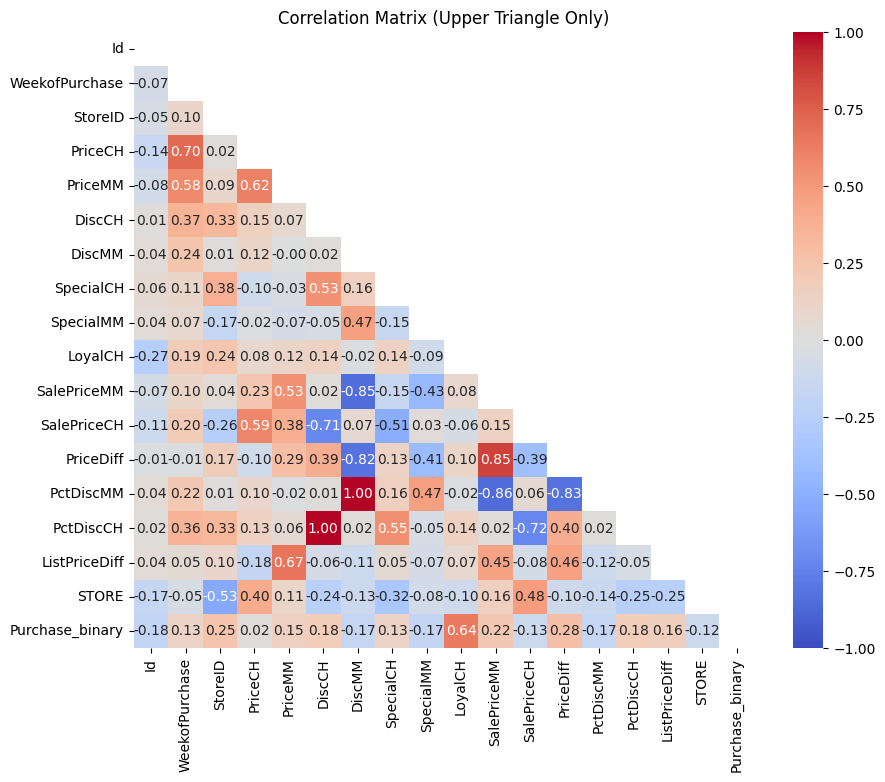

In [154]:
corr = juice_data.corr(numeric_only=True)

# Mask lower triangle (including diagonal)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix (Upper Triangle Only)")
plt.show()

- Remember not to drop columns just yet just loosely be aware they maybe be a possibility of dropping some collinear columns later in the train,test split.

### 6. Outliers & Anomalies

Are outliers real or errors?

- Errors hurt model, real ones may be important
- ✅ Remove errors, keep meaningful extremes

In [125]:
# IQR-based outlier count per column
numeric_data = juice_data.select_dtypes(include='number')

Q1 = numeric_data.quantile(0.25,numeric_only=True)
Q3 = numeric_data.quantile(0.75,numeric_only=True)
IQR = Q3 - Q1

outliers = ((numeric_data < (Q1 - 1.5 * IQR)) | (numeric_data > (Q3 + 1.5 * IQR))).sum()
outliers.sort_values(ascending=False)

PctDiscCH          232
DiscCH             232
SpecialMM          173
SpecialCH          158
SalePriceCH         75
PriceMM             57
DiscMM              47
PctDiscMM           41
PriceDiff           36
Id                   0
WeekofPurchase       0
LoyalCH              0
PriceCH              0
StoreID              0
SalePriceMM          0
ListPriceDiff        0
STORE                0
Purchase_binary      0
dtype: int64

✅ Transform (log, sqrt)
- if skewed distribution

✅ Leave it (if meaningful)

- high income, large purchases

🟡 Moderate outliers → model-dependent decision

Tree models → usually fine

Linear models → more sensitive

## Summary
You just went from raw data to actionable statistical insights in seconds allowing you to support your analysis workflow and focus on the considerations that might apply during train/test split